Code for running results from oxDNA simulation in IO folder path

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
#### set folder path
INPUT_PATH = "IO\\seed_20_job_1243118.pbs-7"

In [4]:
# Check if file exists and use correct path
energy_file = os.path.join(INPUT_PATH, "energy.dat")
last_hist_file = os.path.join(INPUT_PATH, "last_hist.dat")

# Verify the file exists
if not os.path.exists(energy_file):
    print(f"File not found: {energy_file}")
    print(f"Current working directory: {os.getcwd()}")
    print(f"Files in {INPUT_PATH}: {os.listdir(INPUT_PATH) if os.path.exists(INPUT_PATH) else 'Directory does not exist'}")
else:
    # read: whitespace-delimited, ignore comments like '# ...'
    energydf = pd.read_csv(
        energy_file,
        delim_whitespace=True,   # split on any whitespace
        comment="#",             # skip comment lines
        header=None,             # oxDNA often has no header row
        names=["step",
               "potential_energy",
               "acceptance_rate",
               "rotational_acceptance",
               "volume_acceptance",
               "num_bonds",
               "caca",
               "current_weight"],
        engine="python"
    )

if not os.path.exists(last_hist_file):
    print(f"File not found: {last_hist_file}")
    print(f"Current working directory: {os.getcwd()}")
    print(f"Files in {INPUT_PATH}: {os.listdir(INPUT_PATH) if os.path.exists(INPUT_PATH) else 'Directory does not exist'}")
else:
    # read: whitespace-delimited, ignore comments like '# ...'
    lasthistdf = pd.read_csv(
        last_hist_file,
        delim_whitespace=True,   # split on any whitespace
        comment="#",             # skip comment lines
        header=None,             # oxDNA often has no header row
        names=["num_bonds",
               "caca",
               "biased_frequency",
               "bias_corrected_frequency"
               ],
        engine="python"
    )


C:\Users\Tristan\AppData\Local\Temp\ipykernel_13480\3636038776.py:12: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  energydf = pd.read_csv(
C:\Users\Tristan\AppData\Local\Temp\ipykernel_13480\3636038776.py:34: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  lasthistdf = pd.read_csv(


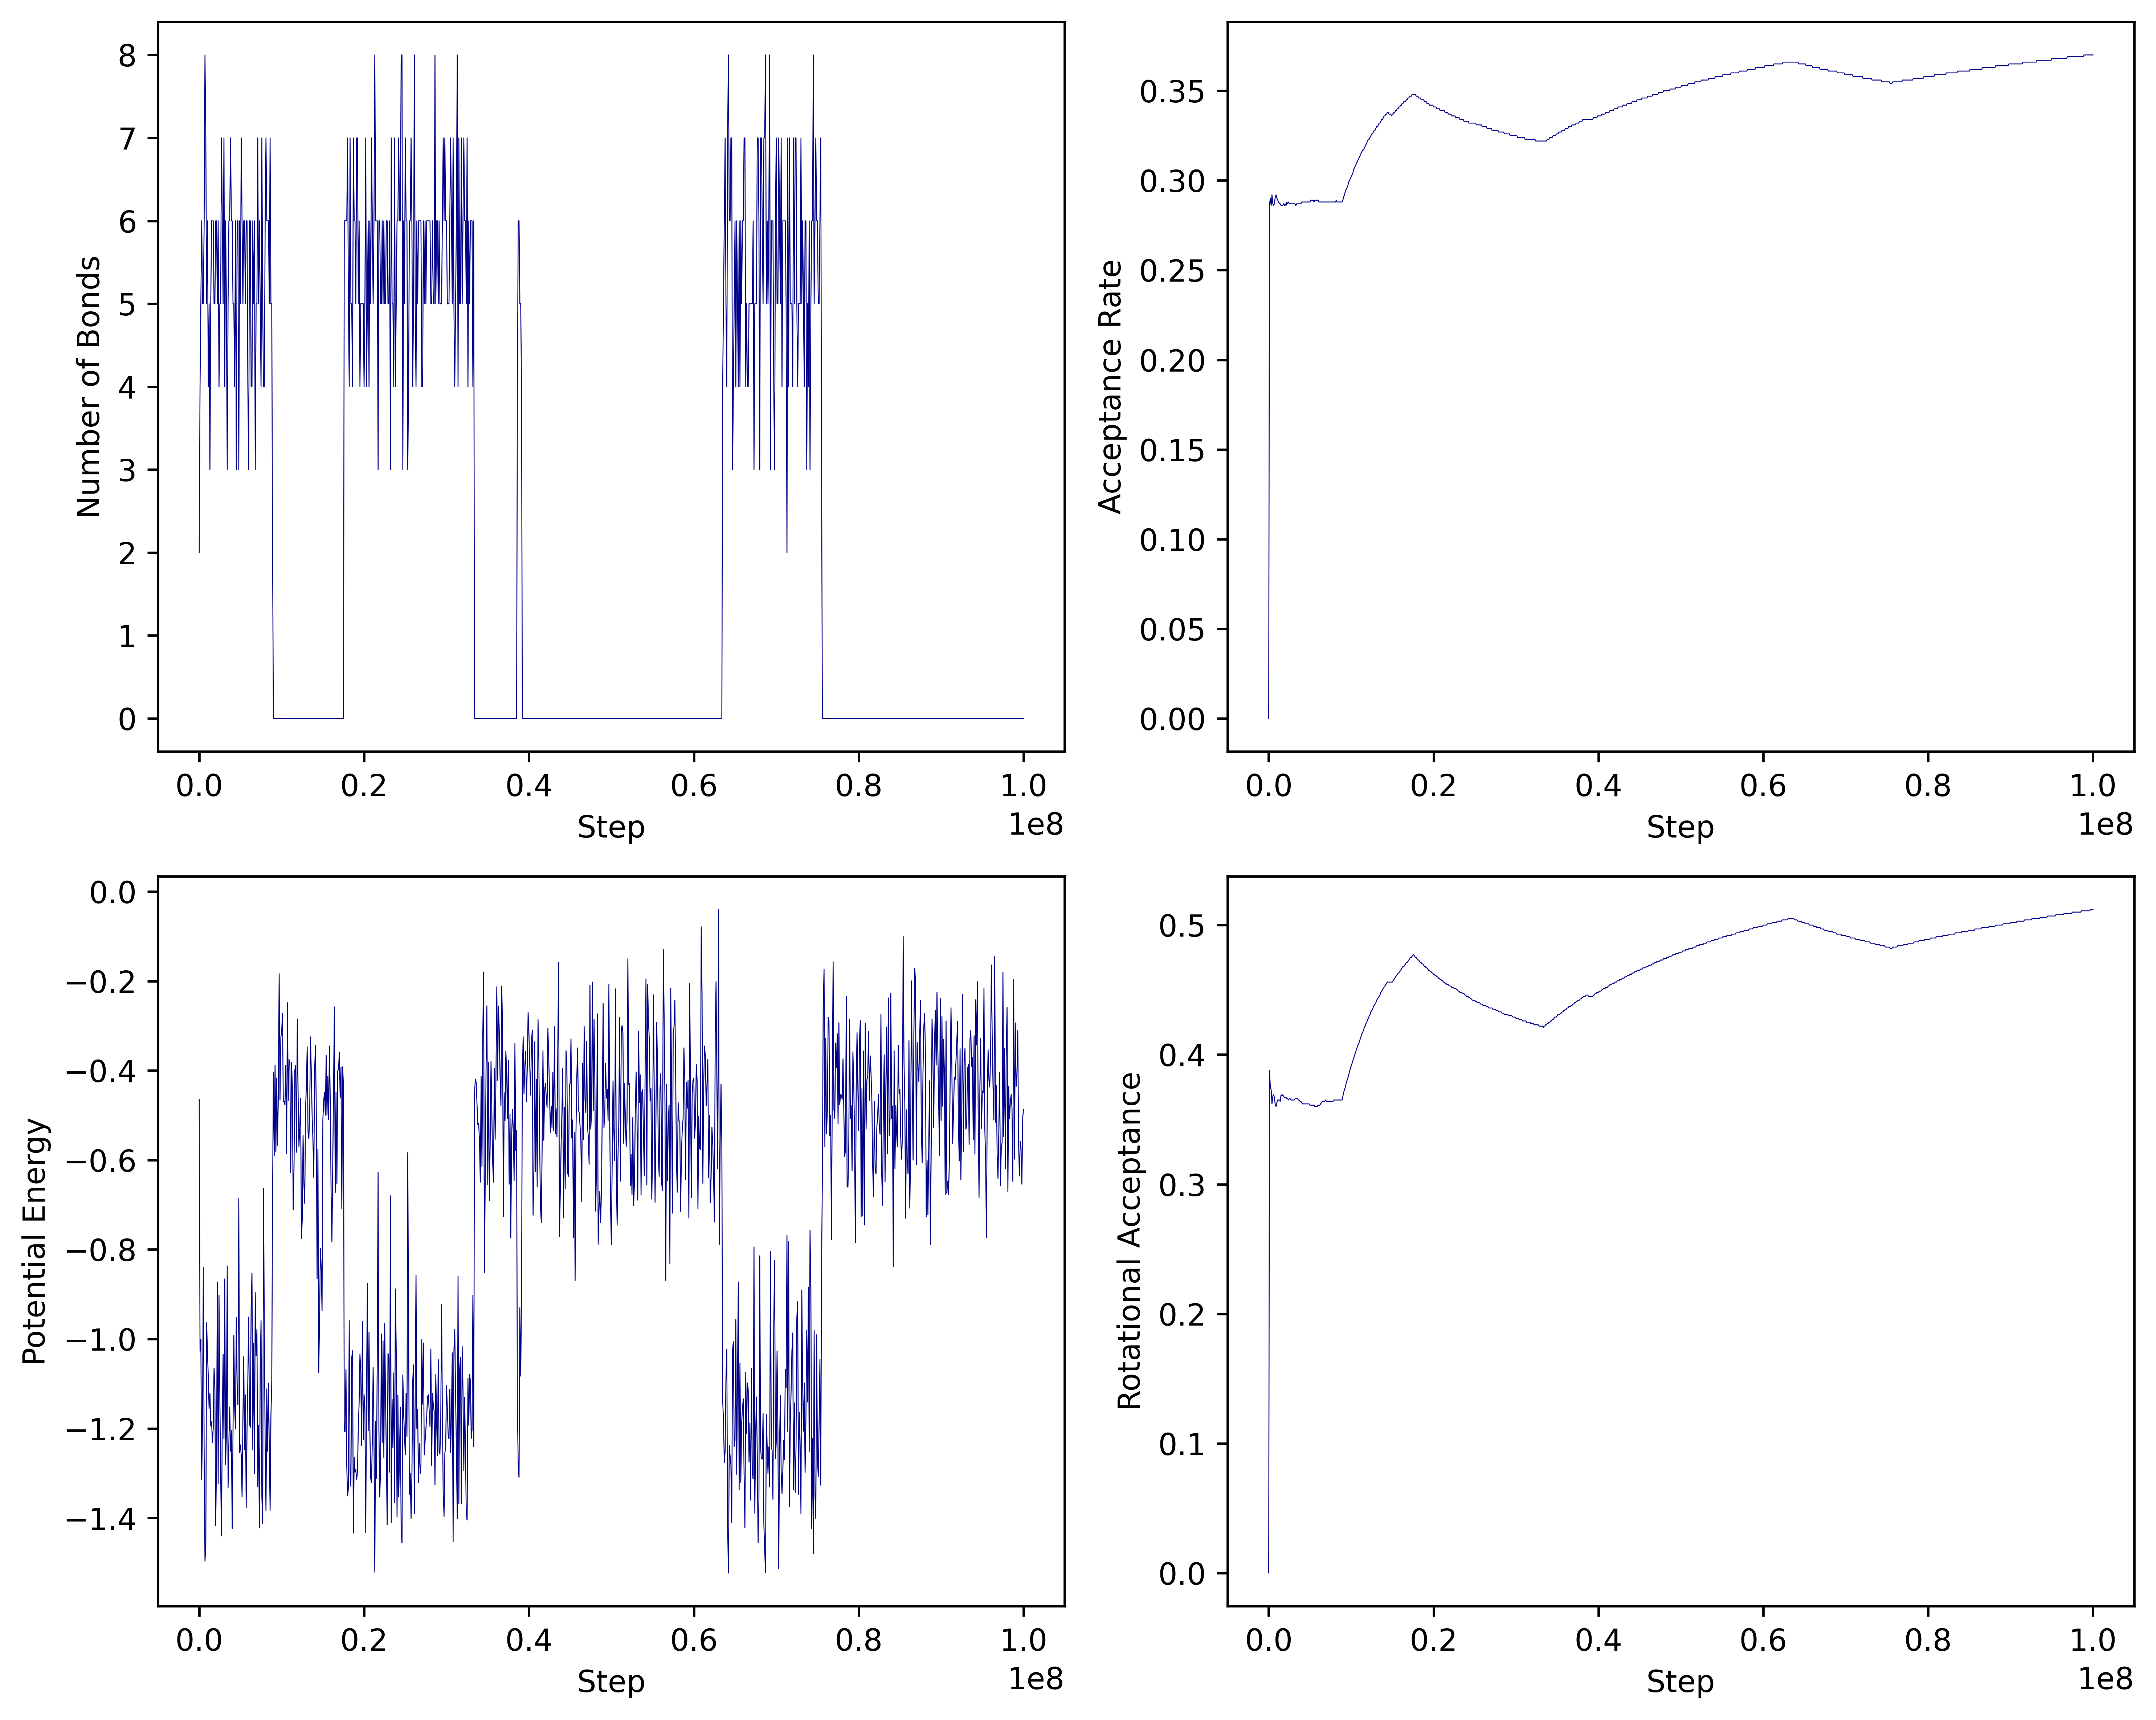

In [5]:
#### plot multiple data profiles from energy.dat
fig, axs = plt.subplots(figsize=(10, 8), dpi=600, nrows=2, ncols=2)
axs[0, 0].plot(energydf["step"], energydf["num_bonds"], color="darkblue", linewidth=0.3)
axs[0, 0].set_xlabel("Step")
axs[0, 0].set_ylabel("Number of Bonds")
axs[1, 0].plot(energydf["step"], energydf["potential_energy"], color="darkblue", linewidth=0.3)
axs[1, 0].set_xlabel("Step")
axs[1, 0].set_ylabel("Potential Energy")
axs[0, 1].plot(energydf["step"], energydf["acceptance_rate"], color="darkblue", linewidth=0.3)
axs[0, 1].set_xlabel("Step")
axs[0, 1].set_ylabel("Acceptance Rate")
axs[1, 1].plot(energydf["step"], energydf["rotational_acceptance"], color="darkblue", linewidth=0.3)
axs[1, 1].set_xlabel("Step")
axs[1, 1].set_ylabel("Rotational Acceptance")
plt.tight_layout()

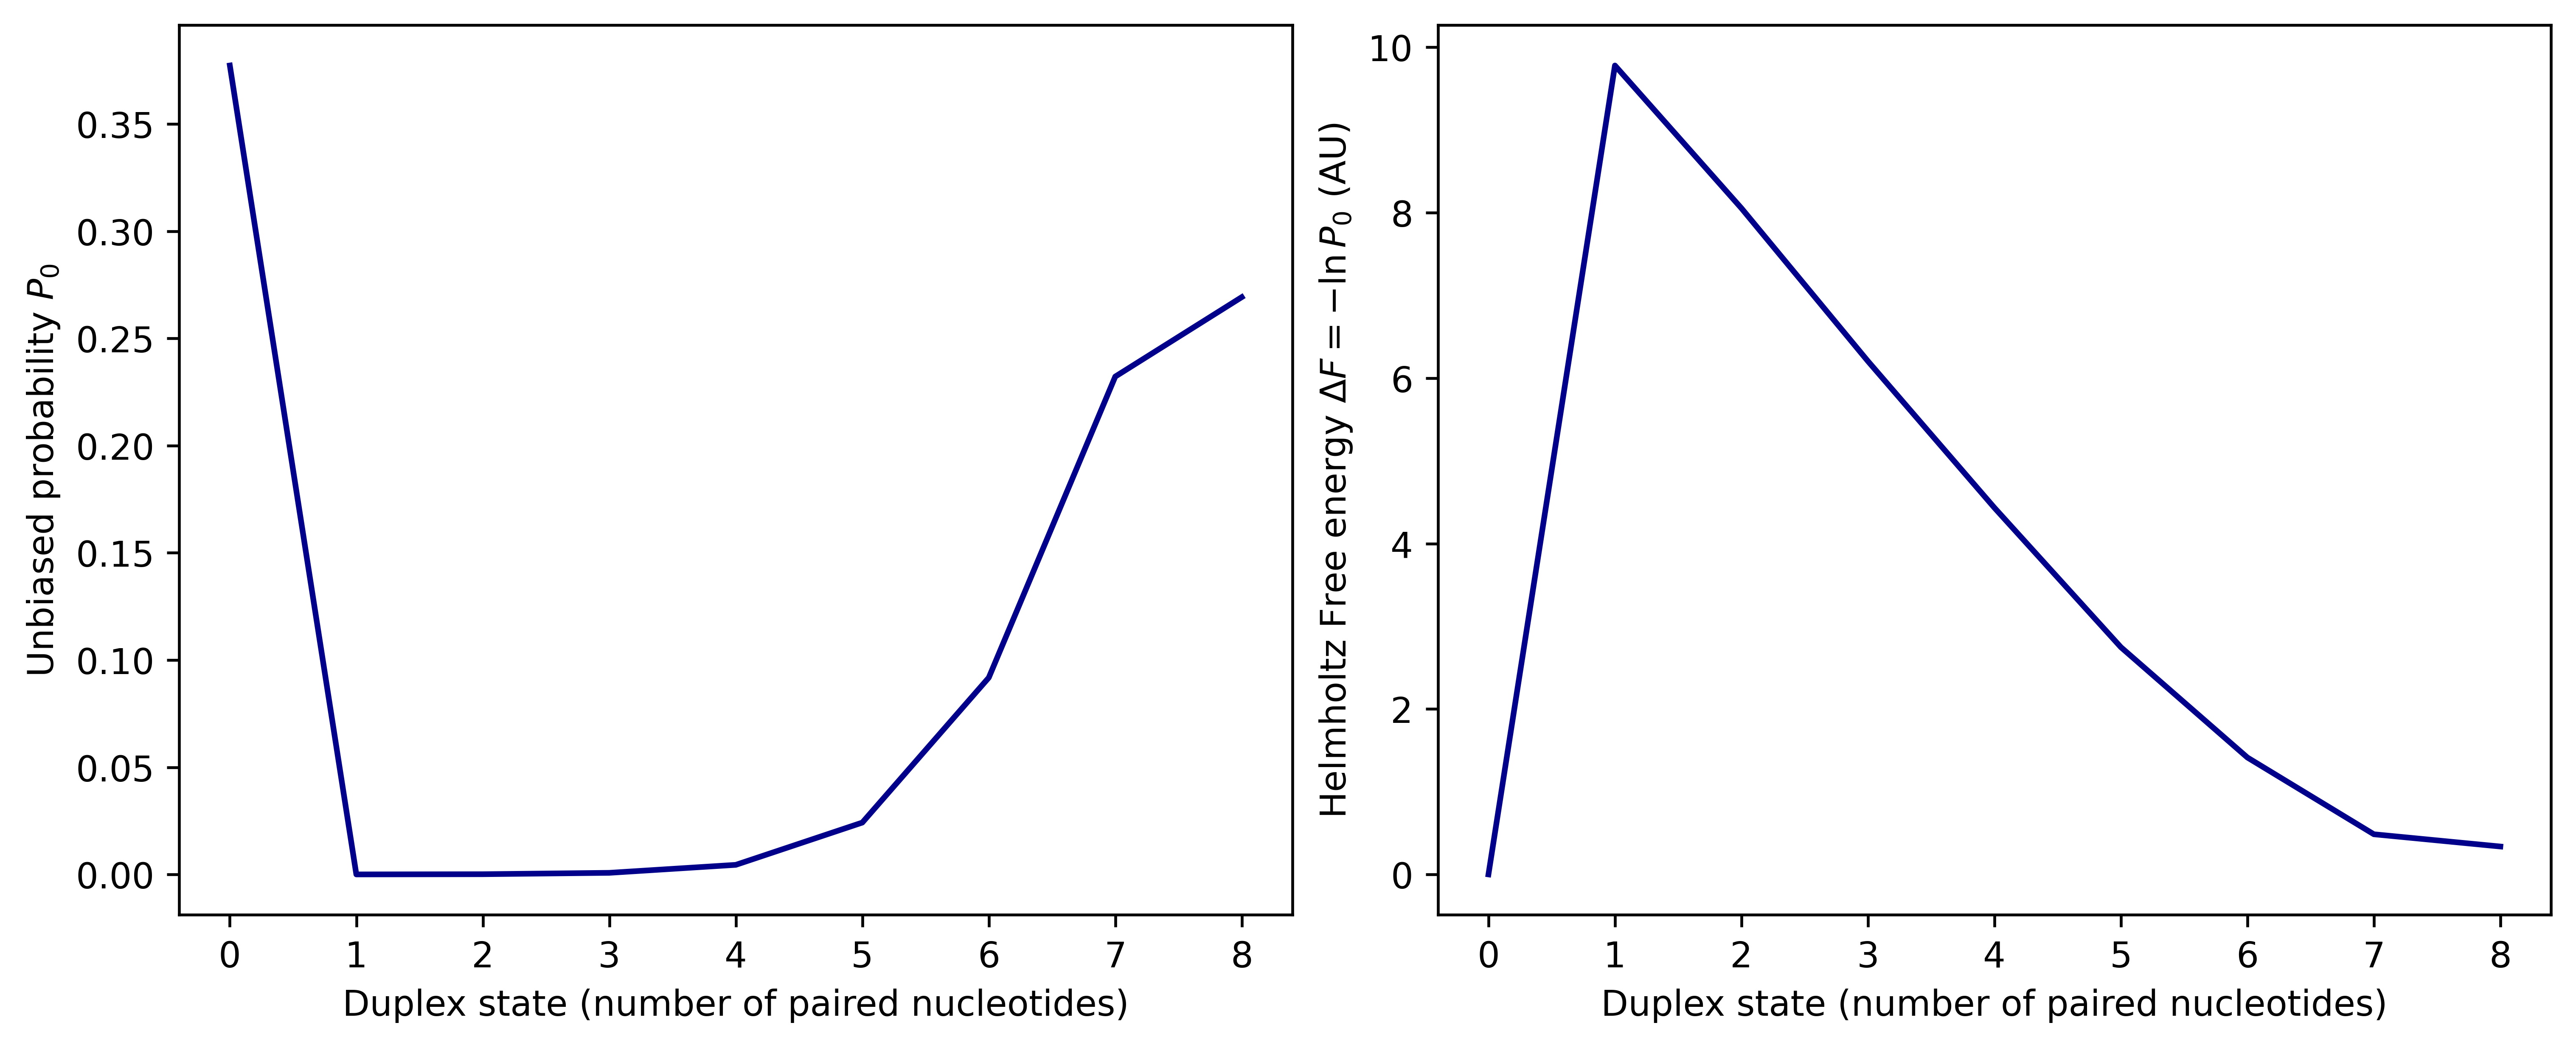

In [ ]:
#### plot probability and Helmholtz free energy profiles
N = lasthistdf.shape[1] - 2

agg = (pd.DataFrame({"op": lasthistdf["num_bonds"], "H0": lasthistdf.iloc[:, N+1]})
       .groupby("op", as_index=False)["H0"].sum()
       .sort_values("op")) # type: ignore because pylance is weird with this

P0 = agg["H0"] / agg["H0"].sum()
F = -np.log(P0)
F -= F.min() # makes the minimum free energy zero

fig, axs = plt.subplots(1, 2, figsize=(10, 4), dpi=600, constrained_layout=True)
axs[0].plot(agg["op"], P0, lw=1.6, color="darkblue")
axs[0].set_xlabel("Duplex state (number of paired nucleotides)")
axs[0].set_ylabel("Unbiased probability $P_0$")

axs[1].plot(agg["op"], F, lw=1.6, color="darkblue")
axs[1].set_xlabel("Duplex state (number of paired nucleotides)")
axs[1].set_ylabel("Helmholtz Free energy $\\Delta F=-\\ln P_0$ (AU)")

plt.show()